<a href="https://colab.research.google.com/github/Keruthika-N/Milestone-1/blob/main/Alzheimer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os

# 🔹 Mount Google Drive
drive.mount('/content/drive')

# 🔹 Search for output.zip in MyDrive
zip_path = None
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if "output.zip" in files:
        zip_path = os.path.join(root, "output.zip")
        break

if zip_path:
    print(f"✅ Found output.zip at: {zip_path}")
else:
    print("❌ output.zip not found. Make sure it's uploaded to Google Drive.")


Mounted at /content/drive
✅ Found output.zip at: /content/drive/MyDrive/output.zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/output.zip"   # path of your dataset
extract_path = "/content/dataset"                # where to extract

# unzip
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset unzipped to:", extract_path)


✅ Dataset unzipped to: /content/dataset


Creating train/val/test splits...
Classes: ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']

Counts in /content/oasis_split_colab/train:
  Mild Dementia: 3499
  Moderate Dementia: 3499
  Non Demented: 3499
  Very mild Dementia: 3499

Counts in /content/oasis_split_colab/val:
  Mild Dementia: 750
  Moderate Dementia: 750
  Non Demented: 750
  Very mild Dementia: 750

Counts in /content/oasis_split_colab/test:
  Mild Dementia: 751
  Moderate Dementia: 751
  Non Demented: 751
  Very mild Dementia: 751
Found 13996 images belonging to 4 classes.
Found 3000 images belonging to 4 classes.
Found 3004 images belonging to 4 classes.
Class indices: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,837,799 (18.45 MB)

 Trainable params: 788,228 (3.01 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
101/438 ━━━━━━━━━━━━━━━━━━━━ 2:13 397ms/step - accuracy: 0.2523 - loss: 1.4127

KeyboardInterrupt: 

In [ ]:
import os

for root, dirs, files in os.walk(extract_path):
    print(root, "->", len(files), "files")
    break  # just to check the top level


/content/dataset -> 0 files


In [ ]:
print(os.listdir(extract_path))


['Non Demented', 'Moderate Dementia', 'Mild Dementia', 'Very mild Dementia']


In [ ]:
for class_folder in os.listdir(extract_path):
    class_path = os.path.join(extract_path, class_folder)
    num_files = len(os.listdir(class_path))
    print(class_folder, "->", num_files, "files")


Non Demented -> 5000 files
Moderate Dementia -> 5000 files
Mild Dementia -> 5000 files
Very mild Dementia -> 5000 files


In [ ]:
# Full advanced-CNN training pipeline (Colab-ready)
# Change BALANCED_DIR to your extracted balanced dataset path if different.
import os
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ========== USER CONFIG ==========
BALANCED_DIR = "/content/dataset"   # <- change if needed
OUTPUT_SPLIT_DIR = "/content/oasis_split_colab"  # where train/val/test will be created
IMG_SIZE = (224, 224)   # input size
BATCH_SIZE = 32
SEED = 42
BACKBONE = "EfficientNetB0"   # choose: "EfficientNetB0", "ResNet50", "Xception"
INITIAL_EPOCHS = 10
FINETUNE_EPOCHS = 10
FINE_TUNE_AT = 20   # number of layers from the end to unfreeze (for fine-tuning)
# =================================

# -- Ensure reproducibility (best-effort)
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# ========== 1) Create train/val/test splits (70/15/15) ==========
def create_splits(src_dir, dest_dir, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=SEED):
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6
    os.makedirs(dest_dir, exist_ok=True)
    train_dir = os.path.join(dest_dir, "train")
    val_dir = os.path.join(dest_dir, "val")
    test_dir = os.path.join(dest_dir, "test")
    for d in [train_dir, val_dir, test_dir]:
        os.makedirs(d, exist_ok=True)

    classes = sorted([d for d in os.listdir(src_dir) if os.path.isdir(os.path.join(src_dir, d))])
    print("Classes:", classes)

    for cls in classes:
        src_cls = os.path.join(src_dir, cls)
        files = [f for f in os.listdir(src_cls) if os.path.isfile(os.path.join(src_cls, f))]
        # shuffle
        files = sorted(files)
        train_files, temp_files = train_test_split(files, test_size=(1 - train_ratio), random_state=seed)
        val_files, test_files = train_test_split(temp_files, test_size=test_ratio/(test_ratio+val_ratio), random_state=seed)
        # create class folders
        for d, file_list in zip([train_dir, val_dir, test_dir], [train_files, val_files, test_files]):
            os.makedirs(os.path.join(d, cls), exist_ok=True)
            for f in file_list:
                shutil.copy(os.path.join(src_cls, f), os.path.join(d, cls, f))
    return train_dir, val_dir, test_dir

# Only create splits if not already present (so you can rerun safely)
if not os.path.exists(os.path.join(OUTPUT_SPLIT_DIR, "train")):
    print("Creating train/val/test splits...")
    train_dir, val_dir, test_dir = create_splits(BALANCED_DIR, OUTPUT_SPLIT_DIR)
else:
    train_dir = os.path.join(OUTPUT_SPLIT_DIR, "train")
    val_dir = os.path.join(OUTPUT_SPLIT_DIR, "val")
    test_dir = os.path.join(OUTPUT_SPLIT_DIR, "test")
    print("Using existing splits in", OUTPUT_SPLIT_DIR)

# quick counts
def print_counts(path):
    print(f"\nCounts in {path}:")
    for cls in sorted(os.listdir(path)):
        p = os.path.join(path, cls)
        if os.path.isdir(p):
            print(f"  {cls}: {len(os.listdir(p))}")
print_counts(train_dir); print_counts(val_dir); print_counts(test_dir)

# ========== 2) Data generators (augmentation for train) ==========
# ========== Fixed Data Generators (preprocessing for backbone) ==========
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_fn,  # backbone-specific preprocessing
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_fn
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    seed=SEED
)

test_gen = val_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# check
print("Class indices:", train_gen.class_indices)


# ========== 3) Model builder (choose backbone + preprocessing) ==========
def get_backbone_and_preprocess(name):
    name = name.lower()
    if "efficient" in name:
        from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input
        base = EfficientNetB0(weights="imagenet", include_top=False, input_shape=IMG_SIZE+(3,))
        return base, preprocess_input
    if "resnet" in name:
        from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
        base = ResNet50(weights="imagenet", include_top=False, input_shape=IMG_SIZE+(3,))
        return base, preprocess_input
    if "xception" in name:
        from tensorflow.keras.applications.xception import Xception, preprocess_input
        base = Xception(weights="imagenet", include_top=False, input_shape=IMG_SIZE+(3,))
        return base, preprocess_input
    # default fallback
    from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input
    return EfficientNetB0(weights="imagenet", include_top=False, input_shape=IMG_SIZE+(3,)), preprocess_input

base_model, preprocess_fn = get_backbone_and_preprocess(BACKBONE)
base_model.trainable = False  # freeze for initial training

from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.models import Model

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(512, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(num_classes, activation="softmax")(x)
model = Model(base_model.input, outputs)

# compile
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# ========== 4) Callbacks ==========
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-7),
    ModelCheckpoint("best_model_initial.h5", monitor="val_accuracy", save_best_only=True, verbose=1)
]

# ========== 5) Optional: compute class weights (helps if you suspect imbalance) ==========
# Here dataset is balanced but this is harmless and useful if splits slightly differ
from sklearn.utils.class_weight import compute_class_weight
all_train_labels = []
for cls_idx, cls_name in enumerate(sorted(class_indices.keys(), key=lambda k:class_indices[k])):
    # count files per class in train_dir
    path = os.path.join(train_dir, cls_name)
    all_train_labels += [cls_idx]*len(os.listdir(path))
all_train_labels = np.array(all_train_labels)
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(all_train_labels), y=all_train_labels)
class_weights = {i: w for i, w in enumerate(class_weights)}
print("Class weights:", class_weights)

# ========== 6) Train head (base frozen) ==========
history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# ========== 7) Fine-tune: unfreeze last layers and continue training ==========
# Unfreeze last `FINE_TUNE_AT` layers of the base_model
base_model.trainable = True
# Freeze all layers except the last FINE_TUNE_AT layers
for layer in base_model.layers[:-FINE_TUNE_AT]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='categorical_crossentropy', metrics=['accuracy'])

callbacks_ft = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7),
    ModelCheckpoint("best_model_finetuned.h5", monitor="val_accuracy", save_best_only=True, verbose=1)
]

history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=FINETUNE_EPOCHS,
    callbacks=callbacks_ft,
    class_weight=class_weights
)

# Save final model
model.save("final_{}_model.h5".format(BACKBONE))

# ========== 8) Evaluate on test set ==========
print("\nEvaluating on Test Set...")
test_steps = int(np.ceil(test_gen.samples / BATCH_SIZE))
y_pred = model.predict(test_gen, steps=test_steps, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

print("\nClassification Report:")
print(classification_report(y_true, y_pred_classes, target_names=[inv_class_indices[i] for i in range(num_classes)]))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_true, y_pred_classes)
print(cm)

# ========== 9) Plot training curves ==========
def plot_history(h1, h2=None):
    plt.figure(figsize=(14,5))
    # accuracy
    plt.subplot(1,2,1)
    plt.plot(h1.history['accuracy'], label='train_acc_initial')
    plt.plot(h1.history['val_accuracy'], label='val_acc_initial')
    if h2:
        plt.plot(h2.history['accuracy'], label='train_acc_finetune')
        plt.plot(h2.history['val_accuracy'], label='val_acc_finetune')
    plt.legend(); plt.title('Accuracy'); plt.grid(True)
    # loss
    plt.subplot(1,2,2)
    plt.plot(h1.history['loss'], label='train_loss_initial')
    plt.plot(h1.history['val_loss'], label='val_loss_initial')
    if h2:
        plt.plot(h2.history['loss'], label='train_loss_finetune')
        plt.plot(h2.history['val_loss'], label='val_loss_finetune')
    plt.legend(); plt.title('Loss'); plt.grid(True)
    plt.show()

plot_history(history1, history2)

# Optional: visualize confusion matrix heatmap
try:
    import seaborn as sns
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=[inv_class_indices[i] for i in range(num_classes)],
                yticklabels=[inv_class_indices[i] for i in range(num_classes)], cmap="Blues")
    plt.ylabel("True"); plt.xlabel("Predicted"); plt.title("Confusion Matrix")
    plt.show()
except Exception:
    print("Seaborn not available — skip heatmap.")


Using existing splits in /content/oasis_split_colab

Counts in /content/oasis_split_colab/train:
  Mild Dementia: 3499
  Moderate Dementia: 3499
  Non Demented: 3499
  Very mild Dementia: 3499

Counts in /content/oasis_split_colab/val:
  Mild Dementia: 750
  Moderate Dementia: 750
  Non Demented: 750
  Very mild Dementia: 750

Counts in /content/oasis_split_colab/test:
  Mild Dementia: 751
  Moderate Dementia: 751
  Non Demented: 751
  Very mild Dementia: 751
Found 13996 images belonging to 4 classes.
Found 3000 images belonging to 4 classes.
Found 3004 images belonging to 4 classes.
Class indices: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_6         │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_3     │ (None, 224, 224,  │          7 │ rescaling_6[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_7         │ (None, 224, 224,  │          0 │ normalization_3[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_7[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,837,799 (18.45 MB)

 Trainable params: 788,228 (3.01 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
389/438 ━━━━━━━━━━━━━━━━━━━━ 20s 416ms/step - accuracy: 0.3939 - loss: 1.2723

KeyboardInterrupt: 

In [ ]:
print("Classes found:", os.listdir(BALANCED_DIR))


Classes found: ['Moderate Dementia', 'Mild Dementia', 'Non Demented', 'Very mild Dementia']


In [ ]:
from tensorflow.keras.models import load_model
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1️⃣ Load the fine-tuned model
model = load_model("best_model_finetuned.h5")  # or final_EfficientNetB0_model.h5

# 2️⃣ Prepare test generator (must match what you used for training)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_gen = test_datagen.flow_from_directory(
    "/content/oasis_split_colab/test",  # your test directory
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# 3️⃣ Evaluate
test_steps = int(np.ceil(test_gen.samples / test_gen.batch_size))
y_pred = model.predict(test_gen, steps=test_steps, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

# 4️⃣ Classification report
class_indices = test_gen.class_indices
inv_class_indices = {v:k for k,v in class_indices.items()}
print(classification_report(y_true, y_pred_classes, target_names=[inv_class_indices[i] for i in range(len(inv_class_indices))]))

# 5️⃣ Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:\n", cm)

# Optional: compute accuracy
accuracy = np.sum(y_pred_classes == y_true) / len(y_true)
print(f"Test Accuracy: {accuracy:.4f}")


Found 3004 images belonging to 4 classes.
94/94 ━━━━━━━━━━━━━━━━━━━━ 19s 126ms/step
                    precision    recall  f1-score   support

     Mild Dementia       0.72      0.79      0.75       751
 Moderate Dementia       1.00      0.87      0.93       751
      Non Demented       0.82      0.76      0.79       751
Very mild Dementia       0.64      0.71      0.67       751

          accuracy                           0.78      3004
         macro avg       0.79      0.78      0.79      3004
      weighted avg       0.79      0.78      0.79      3004

Confusion Matrix:
 [[593   0  20 138]
 [ 58 651   5  37]
 [ 56   0 574 121]
 [116   0 105 530]]
Test Accuracy: 0.7816


Upload either a ZIP of images or multiple image files at once:


Saving 1 (2).jpg to 1 (2).jpg
Saving 1 (3).jpg to 1 (3).jpg
Saving 1 (4).jpg to 1 (4).jpg
Saving 1 (5).jpg to 1 (5).jpg
Saving 1 (6).jpg to 1 (6).jpg
Saving 1 (7).jpg to 1 (7).jpg
Saving 1 (8).jpg to 1 (8).jpg
Saving 1 (9).jpg to 1 (9).jpg
Saving 1 (10).jpg to 1 (10).jpg
Saving 1 (11).jpg to 1 (11).jpg
Saving 1 (12).jpg to 1 (12) (1).jpg
Saving 1 (13).jpg to 1 (13) (1).jpg
Saving 1 (14).jpg to 1 (14) (2).jpg
Saving 1 (15).jpg to 1 (15) (1).jpg
Saving 1 (16).jpg to 1 (16).jpg
Saving 1 (17).jpg to 1 (17).jpg
Saving 1 (18).jpg to 1 (18).jpg
Saving 1 (19).jpg to 1 (19).jpg
Saving 1 (20).jpg to 1 (20).jpg
Saving 1 (21).jpg to 1 (21).jpg
Saving 1 (22).jpg to 1 (22).jpg
Saving 1 (23).jpg to 1 (23).jpg
Saving 1 (24).jpg to 1 (24).jpg
Saving 1 (25).jpg to 1 (25).jpg
Saving 1 (26).jpg to 1 (26).jpg
Saving 1 (27).jpg to 1 (27).jpg
Saving 1 (28).jpg to 1 (28).jpg
Saving 1.jpg to 1.jpg
Saving 2 (2).jpg to 2 (2).jpg
Saving 2 (3).jpg to 2 (3).jpg
Saving 2 (4).jpg to 2 (4).jpg
Saving 2 (5).jpg to 2 (5

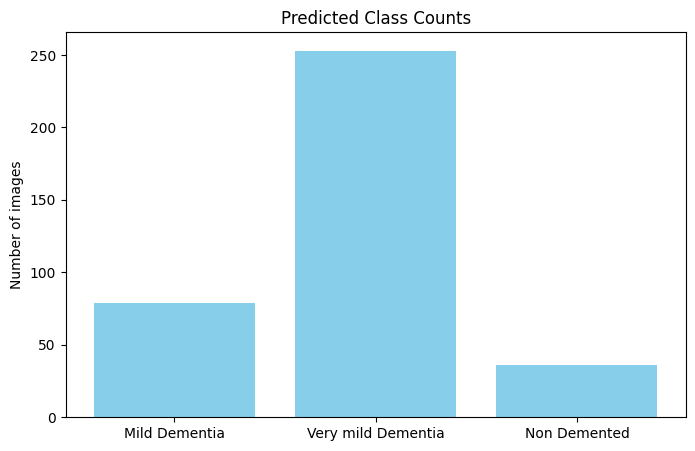

In [ ]:
# =========================
# 1️⃣ Imports
# =========================
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input
from collections import Counter
import matplotlib.pyplot as plt
from google.colab import files
import zipfile

# =========================
# 2️⃣ Load your trained model
# =========================
model = load_model("best_model_finetuned.h5")  # or final_EfficientNetB0_model.h5

# =========================
# 3️⃣ Class mapping
# =========================
class_indices = {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
inv_class_indices = {v:k for k,v in class_indices.items()}

# =========================
# 4️⃣ Upload images
# =========================
print("Upload either a ZIP of images or multiple image files at once:")
uploaded = files.upload()

# Create folder to store images
extract_dir = "/content/test_images"
os.makedirs(extract_dir, exist_ok=True)

# Check if uploaded is ZIP or images
for fn in uploaded.keys():
    if fn.lower().endswith(".zip"):
        # Extract ZIP
        zip_path = "/content/" + fn
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)
        print("ZIP extracted to:", extract_dir)
    else:
        # Move individual image
        os.rename(fn, os.path.join(extract_dir, fn))
        print("Image uploaded to:", os.path.join(extract_dir, fn))

# =========================
# 5️⃣ Prediction function for single image
# =========================
def predict_image(img_path, model):
    img = image.load_img(img_path, target_size=(224,224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    preds = model.predict(x)[0]
    predicted_class = inv_class_indices[np.argmax(preds)]
    return predicted_class

# =========================
# 6️⃣ Batch prediction for all images
# =========================
all_image_paths = []
for root, dirs, files_list in os.walk(extract_dir):
    for f in files_list:
        if f.lower().endswith((".jpg",".jpeg",".png")):
            all_image_paths.append(os.path.join(root, f))

print(f"Total images to predict: {len(all_image_paths)}")

counts = Counter()
for img_path in all_image_paths:
    pred_class = predict_image(img_path, model)
    counts[pred_class] += 1

# =========================
# 7️⃣ Display results
# =========================
print("\nPrediction counts per class:")
for cls, count in counts.items():
    print(f"{cls}: {count}")

# Optional: plot bar chart
plt.figure(figsize=(8,5))
plt.bar(counts.keys(), counts.values(), color='skyblue')
plt.ylabel("Number of images")
plt.title("Predicted Class Counts")
plt.show()


Upload either a ZIP of images or multiple image files at once:


Saving 1 (2).jpg to 1 (2).jpg
Saving 1.jpg to 1.jpg
Saving 2 (2).jpg to 2 (2).jpg
Saving 2.jpg to 2.jpg
Saving 3 (2).jpg to 3 (2).jpg
Saving 3.jpg to 3.jpg
Saving 4 (2).jpg to 4 (2).jpg
Saving 4.jpg to 4.jpg
Saving 5 (2).jpg to 5 (2).jpg
Saving 5.jpg to 5.jpg
Saving 6 (2).jpg to 6 (2).jpg
Saving 6.jpg to 6.jpg
Saving 7 (2).jpg to 7 (2).jpg
Saving 7.jpg to 7.jpg
Saving 8 (2).jpg to 8 (2).jpg
Saving 8.jpg to 8.jpg
Saving 9 (2).jpg to 9 (2).jpg
Saving 9.jpg to 9.jpg
Saving 10 (2).jpg to 10 (2).jpg
Saving 10.jpg to 10.jpg
Saving 11 (2).jpg to 11 (2).jpg
Saving 11.jpg to 11.jpg
Saving 12 (2).jpg to 12 (2).jpg
Saving 12.jpg to 12.jpg
Saving 13 (2).jpg to 13 (2).jpg
Saving 13.jpg to 13.jpg
Saving 14 (2).jpg to 14 (2).jpg
Saving 14.jpg to 14.jpg
Saving 15 (2).jpg to 15 (2).jpg
Saving 15.jpg to 15.jpg
Saving 16 (2).jpg to 16 (2).jpg
Saving 16.jpg to 16.jpg
Saving 17 (2).jpg to 17 (2).jpg
Saving 17.jpg to 17.jpg
Saving 18 (2).jpg to 18 (2).jpg
Saving 18.jpg to 18.jpg
Saving 19 (2).jpg to 19 (2).

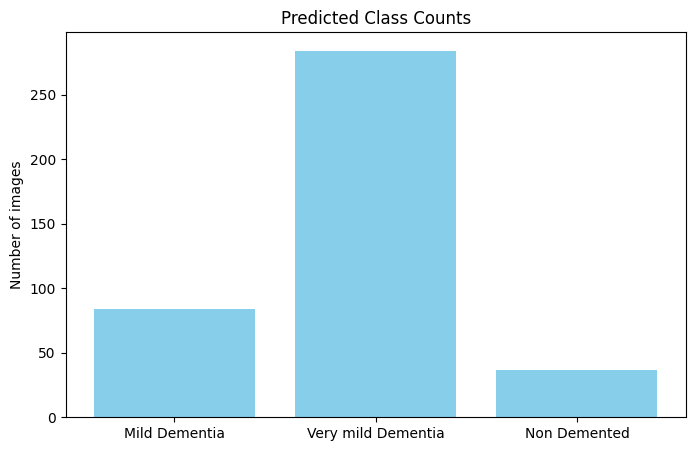

In [ ]:
# =========================
# 1️⃣ Imports
# =========================
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input
from collections import Counter
import matplotlib.pyplot as plt
from google.colab import files
import zipfile

# =========================
# 2️⃣ Load your trained model
# =========================
model = load_model("best_model_finetuned.h5")  # or final_EfficientNetB0_model.h5

# =========================
# 3️⃣ Class mapping
# =========================
class_indices = {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
inv_class_indices = {v:k for k,v in class_indices.items()}

# =========================
# 4️⃣ Upload images
# =========================
print("Upload either a ZIP of images or multiple image files at once:")
uploaded = files.upload()

# Create folder to store images
extract_dir = "/content/test_images"
os.makedirs(extract_dir, exist_ok=True)

# Check if uploaded is ZIP or images
for fn in uploaded.keys():
    if fn.lower().endswith(".zip"):
        # Extract ZIP
        zip_path = "/content/" + fn
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)
        print("ZIP extracted to:", extract_dir)
    else:
        # Move individual image
        os.rename(fn, os.path.join(extract_dir, fn))
        print("Image uploaded to:", os.path.join(extract_dir, fn))

# =========================
# 5️⃣ Prediction function for single image
# =========================
def predict_image(img_path, model):
    img = image.load_img(img_path, target_size=(224,224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    preds = model.predict(x)[0]
    predicted_class = inv_class_indices[np.argmax(preds)]
    return predicted_class

# =========================
# 6️⃣ Batch prediction for all images
# =========================
all_image_paths = []
for root, dirs, files_list in os.walk(extract_dir):
    for f in files_list:
        if f.lower().endswith((".jpg",".jpeg",".png")):
            all_image_paths.append(os.path.join(root, f))

print(f"Total images to predict: {len(all_image_paths)}")

counts = Counter()
for img_path in all_image_paths:
    pred_class = predict_image(img_path, model)
    counts[pred_class] += 1

# =========================
# 7️⃣ Display results
# =========================
print("\nPrediction counts per class:")
for cls, count in counts.items():
    print(f"{cls}: {count}")

# Optional: plot bar chart
plt.figure(figsize=(8,5))
plt.bar(counts.keys(), counts.values(), color='skyblue')
plt.ylabel("Number of images")
plt.title("Predicted Class Counts")
plt.show()


In [ ]:
# =========================
# 1️⃣ Imports
# =========================
import os
import random
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input
import tensorflow as tf

# =========================
# 2️⃣ Config
# =========================
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
INITIAL_EPOCHS = 10
FINETUNE_EPOCHS = 10
FINE_TUNE_AT = 20  # unfreeze last N layers
BACKBONE = "EfficientNetB0"

BALANCED_DIR = ""  # Path to your balanced dataset
OUTPUT_SPLIT_DIR = "/content/oasis_split_colab"

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# =========================
# 3️⃣ Create train/val/test splits
# =========================
def create_splits(src_dir, dest_dir, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=SEED):
    os.makedirs(dest_dir, exist_ok=True)
    train_dir = os.path.join(dest_dir, "train")
    val_dir = os.path.join(dest_dir, "val")
    test_dir = os.path.join(dest_dir, "test")
    for d in [train_dir, val_dir, test_dir]:
        os.makedirs(d, exist_ok=True)

    classes = sorted([d for d in os.listdir(src_dir) if os.path.isdir(os.path.join(src_dir, d))])
    print("Classes:", classes)

    for cls in classes:
        src_cls = os.path.join(src_dir, cls)
        files = [f for f in os.listdir(src_cls) if os.path.isfile(os.path.join(src_cls, f))]
        files = sorted(files)
        train_files, temp_files = train_test_split(files, test_size=(1-train_ratio), random_state=seed)
        val_files, test_files = train_test_split(temp_files, test_size=test_ratio/(test_ratio+val_ratio), random_state=seed)
        for d, file_list in zip([train_dir, val_dir, test_dir], [train_files, val_files, test_files]):
            os.makedirs(os.path.join(d, cls), exist_ok=True)
            for f in file_list:
                os.replace(os.path.join(src_cls, f), os.path.join(d, cls, f))  # move to avoid duplicates
    return train_dir, val_dir, test_dir

if not os.path.exists(os.path.join(OUTPUT_SPLIT_DIR, "train")):
    print("Creating train/val/test splits...")
    train_dir, val_dir, test_dir = create_splits(BALANCED_DIR, OUTPUT_SPLIT_DIR)
else:
    train_dir = os.path.join(OUTPUT_SPLIT_DIR, "train")
    val_dir = os.path.join(OUTPUT_SPLIT_DIR, "val")
    test_dir = os.path.join(OUTPUT_SPLIT_DIR, "test")
    print("Using existing splits in", OUTPUT_SPLIT_DIR)

# =========================
# 4️⃣ Data generators
# =========================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = train_datagen.flow_from_directory(train_dir, target_size=IMG_SIZE,
                                              batch_size=BATCH_SIZE, class_mode='categorical', seed=SEED)
val_gen = val_datagen.flow_from_directory(val_dir, target_size=IMG_SIZE,
                                          batch_size=BATCH_SIZE, class_mode='categorical', seed=SEED)
test_gen = val_datagen.flow_from_directory(test_dir, target_size=IMG_SIZE,
                                           batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)

class_indices = train_gen.class_indices
inv_class_indices = {v:k for k,v in class_indices.items()}
num_classes = len(class_indices)
print("Class indices:", class_indices)

# =========================
# 5️⃣ Compute class weights
# =========================
all_train_labels = []
for cls_idx, cls_name in enumerate(sorted(class_indices.keys(), key=lambda k:class_indices[k])):
    path = os.path.join(train_dir, cls_name)
    all_train_labels += [cls_idx]*len(os.listdir(path))
all_train_labels = np.array(all_train_labels)
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(all_train_labels), y=all_train_labels)
class_weights = {i:w for i,w in enumerate(class_weights)}
print("Class weights:", class_weights)

# =========================
# 6️⃣ Build model
# =========================
base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=IMG_SIZE+(3,))
base_model.trainable = False  # freeze base

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(512, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(num_classes, activation="softmax")(x)
model = Model(base_model.input, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

# =========================
# 7️⃣ Callbacks
# =========================
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-7),
    ModelCheckpoint("best_model_initial.h5", monitor="val_accuracy", save_best_only=True, verbose=1)
]

# =========================
# 8️⃣ Train head (base frozen)
# =========================
history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# =========================
# 9️⃣ Fine-tune last layers
# =========================
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_AT]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

callbacks_ft = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7),
    ModelCheckpoint("best_model_finetuned.h5", monitor="val_accuracy", save_best_only=True, verbose=1)
]

history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=FINETUNE_EPOCHS,
    callbacks=callbacks_ft,
    class_weight=class_weights
)

# =========================
# 10️⃣ Save final model
# =========================
model.save("final_EfficientNetB0_model.h5")

# =========================
# 11️⃣ Evaluate on test set
# =========================
print("\nEvaluating on Test Set...")
test_steps = int(np.ceil(test_gen.samples / BATCH_SIZE))
y_pred = model.predict(test_gen, steps=test_steps, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

from sklearn.metrics import classification_report, confusion_matrix
print("\nClassification Report:")
print(classification_report(y_true, y_pred_classes, target_names=[inv_class_indices[i] for i in range(num_classes)]))

cm = confusion_matrix(y_true, y_pred_classes)
print("\nConfusion Matrix:\n", cm)


Using existing splits in /content/oasis_split_colab
Found 13996 images belonging to 4 classes.
Found 3000 images belonging to 4 classes.
Found 3004 images belonging to 4 classes.
Class indices: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_8         │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_4     │ (None, 224, 224,  │          7 │ rescaling_8[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_9         │ (None, 224, 224,  │          0 │ normalization_4[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_9[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,837,799 (18.45 MB)

 Trainable params: 788,228 (3.01 MB)

...

438/438 ━━━━━━━━━━━━━━━━━━━━ 177s 404ms/step - accuracy: 0.7362 - loss: 0.6188 - val_accuracy: 0.7680 - val_loss: 0.5792 - learning_rate: 1.0000e-05
Epoch 8/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - accuracy: 0.7420 - loss: 0.6150
Epoch 8: val_accuracy improved from 0.76800 to 0.77767, saving model to best_model_finetuned.h5


438/438 ━━━━━━━━━━━━━━━━━━━━ 176s 403ms/step - accuracy: 0.7420 - loss: 0.6150 - val_accuracy: 0.7777 - val_loss: 0.5544 - learning_rate: 1.0000e-05
Epoch 9/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.7477 - loss: 0.5888
Epoch 9: val_accuracy improved from 0.77767 to 0.78633, saving model to best_model_finetuned.h5


438/438 ━━━━━━━━━━━━━━━━━━━━ 176s 401ms/step - accuracy: 0.7477 - loss: 0.5888 - val_accuracy: 0.7863 - val_loss: 0.5395 - learning_rate: 1.0000e-05
Epoch 10/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.7613 - loss: 0.5765
Epoch 10: val_accuracy improved from 0.78633 to 0.78933, saving model to best_model_finetuned.h5


438/438 ━━━━━━━━━━━━━━━━━━━━ 179s 409ms/step - accuracy: 0.7613 - loss: 0.5765 - val_accuracy: 0.7893 - val_loss: 0.5277 - learning_rate: 1.0000e-05



Evaluating on Test Set...
94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step

Classification Report:
                    precision    recall  f1-score   support

     Mild Dementia       0.72      0.79      0.75       751
 Moderate Dementia       1.00      0.87      0.93       751
      Non Demented       0.82      0.76      0.79       751
Very mild Dementia       0.64      0.71      0.67       751

          accuracy                           0.78      3004
         macro avg       0.79      0.78      0.79      3004
      weighted avg       0.79      0.78      0.79      3004


Confusion Matrix:
 [[593   0  20 138]
 [ 58 651   5  37]
 [ 55   0 574 122]
 [116   0 105 530]]


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/oasis_split_colab/test",
    target_size=(224,224),  # use the size you trained with
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/oasis_split_colab/test'


🔹 Model Summary:


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_8         │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_4     │ (None, 224, 224,  │          7 │ rescaling_8[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_9         │ (None, 224, 224,  │          0 │ normalization_4[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_9[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 9,116,177 (34.78 MB)

 Trainable params: 2,139,188 (8.16 MB)

...

 Optimizer params: 4,278,378 (16.32 MB)


🔹 Evaluating on Test Set...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - accuracy: 0.2513 - loss: 1.3979
✅ Test Accuracy: 0.2500 | Test Loss: 1.4941
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step

🔹 Classification Report:
                    precision    recall  f1-score   support

     Mild Dementia       0.00      0.00      0.00       751
 Moderate Dementia       0.25      1.00      0.40       751
      Non Demented       0.00      0.00      0.00       751
Very mild Dementia       0.00      0.00      0.00       751

          accuracy                           0.25      3004
         macro avg       0.06      0.25      0.10      3004
      weighted avg       0.06      0.25      0.10      3004



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


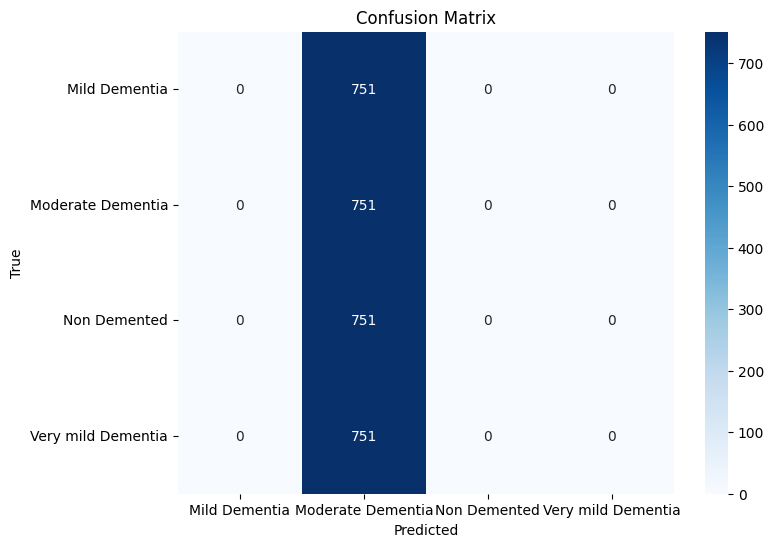


🔹 Per-Class Accuracy:
                Class  Accuracy
0       Mild Dementia       0.0
1   Moderate Dementia       1.0
2        Non Demented       0.0
3  Very mild Dementia       0.0


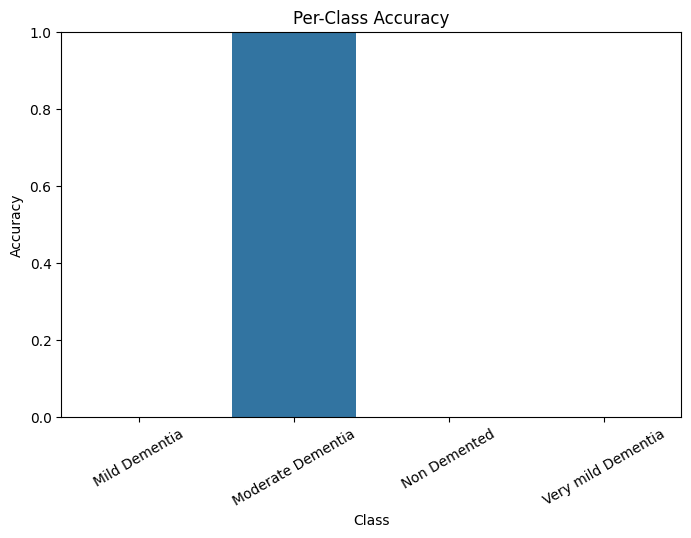

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# ----------------------------
# 1. Model Architecture
# ----------------------------
print("\n🔹 Model Summary:")
model.summary()

# ----------------------------
# 2. Training History
# ----------------------------
# Assuming you have "history" from model.fit()
if 'history' in globals():
    history_dict = history.history

    # Accuracy plot
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(history_dict['accuracy'], label='Train Acc')
    plt.plot(history_dict['val_accuracy'], label='Val Acc')
    plt.title("Model Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss plot
    plt.subplot(1,2,2)
    plt.plot(history_dict['loss'], label='Train Loss')
    plt.plot(history_dict['val_loss'], label='Val Loss')
    plt.title("Model Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.show()

# ----------------------------
# 3. Evaluation on Test Set
# ----------------------------
print("\n🔹 Evaluating on Test Set...")
test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f"✅ Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

# Predictions
y_pred_probs = model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# ----------------------------
# 4. Classification Report
# ----------------------------
print("\n🔹 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))

# ----------------------------
# 5. Confusion Matrix
# ----------------------------
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# ----------------------------
# 6. Per-Class Accuracy
# ----------------------------
cm_sum = np.sum(cm, axis=1, keepdims=True)
per_class_acc = cm.diagonal() / cm_sum.flatten()

df_class_acc = pd.DataFrame({
    "Class": class_labels,
    "Accuracy": per_class_acc
})

print("\n🔹 Per-Class Accuracy:")
print(df_class_acc)

plt.figure(figsize=(8,5))
sns.barplot(x="Class", y="Accuracy", data=df_class_acc)
plt.title("Per-Class Accuracy")
plt.xticks(rotation=30)
plt.ylim(0,1)
plt.show()


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# -------------------------------
# 1. Data Generators
# -------------------------------
train_dir = "/content/oasis_split_colab/train"
val_dir   = "/content/oasis_split_colab/val"
test_dir  = "/content/oasis_split_colab/test"

train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=20,
                                   width_shift_range=0.1,
                                   height_shift_range=0.1,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(176,176),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(176,176),
    batch_size=32,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(176,176),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# -------------------------------
# 2. CNN Model
# -------------------------------
model = keras.models.Sequential([
    keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(176,176,3)),
    keras.layers.MaxPooling2D(),

    keras.layers.Conv2D(32, (2, 2), activation='relu'),
    keras.layers.MaxPooling2D(),

    keras.layers.SeparableConv2D(64, 3, activation='relu', padding='same'),
    keras.layers.SeparableConv2D(64, 3, activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(),

    keras.layers.SeparableConv2D(128, 3, activation='relu', padding='same'),
    keras.layers.SeparableConv2D(128, 3, activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(),
    keras.layers.Dropout(0.2),

    keras.layers.SeparableConv2D(256, 3, activation='relu', padding='same'),
    keras.layers.SeparableConv2D(256, 3, activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(),
    keras.layers.Dropout(0.2),

    keras.layers.Flatten(),

    keras.layers.Dense(512, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.7),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(64, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(4, activation ='softmax')
])

# -------------------------------
# 3. Compile Model
# -------------------------------
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# -------------------------------
# 4. Callbacks
# -------------------------------
callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-6),
    ModelCheckpoint("cnn_model.h5", save_best_only=True, monitor="val_accuracy")
]

# -------------------------------
# 5. Train
# -------------------------------
EPOCHS = 50   # <<<<<< CHANGE THIS VALUE ANYTIME
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks
)

# -------------------------------
# 6. Evaluate
# -------------------------------
loss, acc = model.evaluate(test_generator)
print(f"✅ CNN Test Accuracy: {acc:.4f}, Loss: {loss:.4f}")

# -------------------------------
# 7. Save Model
# -------------------------------
model.save("cnn_model.h5")
print("📂 Model saved as cnn_model.h5")


FileNotFoundError: [Errno 2] No such file or directory: '/content/oasis_split_colab/train'

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from random import randint

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Paths
default_dir = "/content/dataset"
root_dir = "./"
train_dir = default_dir + "train/"
work_dir = root_dir + "dataset/"

# Clean & copy dataset into work_dir
if os.path.exists(work_dir):
    import shutil
    shutil.rmtree(work_dir)

os.mkdir(work_dir)

from distutils.dir_util import copy_tree
copy_tree(train_dir, work_dir)

print("✅ Working Directory Contents:", os.listdir(work_dir))

# Class labels
CLASSES = ['NonDemented', 'VeryMildDemented', 'MildDemented', 'ModerateDemented']
IMG_SIZE = 176


DistutilsFileError: cannot copy tree '/content/datasettrain/': not a directory

In [ ]:
import os

base_dir = "/content/drive/MyDrive/alzheimers-dataset/"

print("Contents of dataset folder:", os.listdir(base_dir))


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/alzheimers-dataset/'

In [ ]:
import os

print("Contents of extracted dataset:", os.listdir("/content/dataset"))


Contents of extracted dataset: ['Moderate Dementia', 'Mild Dementia', 'Non Demented', 'Very mild Dementia']


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/output.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    file_list = zip_ref.namelist()
    print("Total files in ZIP:", len(file_list))
    print("\nSample (first 20 paths):")
    print(file_list[:20])


Total files in ZIP: 20004

Sample (first 20 paths):
['Mild Dementia/', 'Moderate Dementia/', 'Non Demented/', 'Very mild Dementia/', 'Moderate Dementia/aug_5b0c42ae8c8b4aa5a8c45782a393c639.jpg', 'Moderate Dementia/OAS1_0351_MR1_mpr-2_154.jpg', 'Moderate Dementia/aug_38683183ab674ad0932c9d9c14fc8e4d.jpg', 'Moderate Dementia/aug_28badcacbf014c23acbe3bda1c498588.jpg', 'Moderate Dementia/aug_0231112c31f444f882644dafb304fb53.jpg', 'Moderate Dementia/aug_b2cede5a86b447969a36e565aa4c6d20.jpg', 'Moderate Dementia/OAS1_0308_MR1_mpr-1_101.jpg', 'Moderate Dementia/aug_4f52d832cc3346ec9f31d827fec73059.jpg', 'Moderate Dementia/aug_a7f0dcb1bd08471eabc91a8a7c611a89.jpg', 'Moderate Dementia/aug_0b2849959b164249889b6626194a652a.jpg', 'Moderate Dementia/aug_281eeb6f16a7440f95b77c4936141a66.jpg', 'Moderate Dementia/aug_4f29cdb67187470d9cd9b17f21a79023.jpg', 'Moderate Dementia/aug_d9995bbb046541f99950512e380bceeb.jpg', 'Moderate Dementia/aug_85cda0a0ec994c7c9ac3f7e6437d883f.jpg', 'Moderate Dementia/aug_11

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/output.zip"
extract_path = "/content/dataset"

# Clean old folder if exists
if os.path.exists(extract_path):
    import shutil
    shutil.rmtree(extract_path)

# Extract fresh
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset unzipped to:", extract_path)
print("Contents:", os.listdir(extract_path))


✅ Dataset unzipped to: /content/dataset
Contents: ['Moderate Dementia', 'Mild Dementia', 'Non Demented', 'Very mild Dementia']


In [ ]:
!pip install split-folders
import splitfolders
input_dir = "/content/dataset"
output_dir = "/content/oasis_split_colab"

# 70% train, 15% val, 15% test
splitfolders.ratio(input_dir, output=output_dir, seed=42, ratio=(0.7, 0.15, 0.15))

print("✅ Splitting done! Folder structure created at:", output_dir)
print("Subfolders:", os.listdir(output_dir))


Copying files: 20000 files [00:02, 7818.77 files/s]

✅ Splitting done! Folder structure created at: /content/oasis_split_colab
Subfolders: ['train', 'test', 'val']


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 176
BATCH_SIZE = 32
work_dir = "/content/oasis_split_colab"   # after splitfolders

# Train generator
train_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    directory=f"{work_dir}/train",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

# Validation generator
val_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    directory=f"{work_dir}/val",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

# Test generator
test_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    directory=f"{work_dir}/test",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)


Found 14000 images belonging to 4 classes.
Found 3000 images belonging to 4 classes.
Found 3000 images belonging to 4 classes.


In [ ]:
import tensorflow as tf
from tensorflow import keras

IMG_SIZE = 176  # example, set to your input size

model = keras.models.Sequential([
    keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    keras.layers.MaxPooling2D(),

    keras.layers.Conv2D(32, (2, 2), activation='relu'),
    keras.layers.MaxPooling2D(),

    keras.layers.Conv2D(64, (2, 2), activation='relu'),
    keras.layers.MaxPooling2D(),

    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(30, activation='softmax')  # change 30 to your number of classes
])

model = keras.models.Sequential([
    keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(IMG_SIZE,IMG_SIZE,3)),
    keras.layers.MaxPooling2D(),

    keras.layers.Conv2D(32, (2, 2), activation='relu'),
    keras.layers.MaxPooling2D(),

    keras.layers.SeparableConv2D(64, 3, activation='relu', padding='same'),
    keras.layers.SeparableConv2D(64, 3, activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(),

    keras.layers.SeparableConv2D(128, 3, activation='relu', padding='same'),
    keras.layers.SeparableConv2D(128, 3, activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(),
    keras.layers.Dropout(0.2),

    keras.layers.SeparableConv2D(256, 3, activation='relu', padding='same'),
    keras.layers.SeparableConv2D(256, 3, activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(),
    keras.layers.Dropout(0.2),

    keras.layers.Flatten(),

    keras.layers.Dense(512, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.7),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(64, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss=keras.losses.CategoricalCrossentropy(),
    metrics=[keras.metrics.CategoricalAccuracy(name='acc'),
             keras.metrics.AUC(name='auc')]
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 174, 174, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 87, 87, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 86, 86, 32)     │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 43, 43, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 43, 43, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 43, 43, 64)     │         4,736 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 43, 43, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 21, 21, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 21, 21, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 21, 21, 128)    │        17,664 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 21, 21, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_4              │ (None, 10, 10, 256)    │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_5              │ (None, 10, 10, 256)    │        68,096 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,494,596 (13.33 MB)

 Trainable params: 3,492,292 (13.32 MB)

 Non-trainable params: 2,304 (9.00 KB)

In [ ]:
EPOCHS = 50

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 80s 130ms/step - acc: 0.4372 - auc: 0.7009 - loss: 1.4172 - val_acc: 0.2500 - val_auc: 0.5935 - val_loss: 1.8075
Epoch 2/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 32s 55ms/step - acc: 0.6604 - auc: 0.8933 - loss: 0.7743 - val_acc: 0.3773 - val_auc: 0.7407 - val_loss: 1.8129
Epoch 3/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 24s 54ms/step - acc: 0.7577 - auc: 0.9381 - loss: 0.5919 - val_acc: 0.7237 - val_auc: 0.9154 - val_loss: 0.8500
Epoch 4/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 24s 55ms/step - acc: 0.8060 - auc: 0.9593 - loss: 0.4792 - val_acc: 0.4340 - val_auc: 0.6912 - val_loss: 3.3967
Epoch 5/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - acc: 0.8419 - auc: 0.9700 - loss: 0.4077 - val_acc: 0.4290 - val_auc: 0.7580 - val_loss: 2.4749
Epoch 6/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 24s 55ms/step - acc: 0.8676 - auc: 0.9775 - loss: 0.3501 - val_acc: 0.3263 - val_auc: 0.5776 - val_loss: 5.9432
Epoch 7/50
438/438 ━━━━━━━━━━━━━━━━━━━━ 23s 53ms/step - acc: 0.8859 - auc: 0.9817 - los

In [ ]:
model.save("cnn_model.h5")

NameError: name 'model' is not defined

In [ ]:
from tensorflow.keras.models import load_model

# load your pre-trained model
model = load_model("cnn_model.h5")   # or "final_functional_model.h5"


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'cnn_model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)